# Geometric & Intensity Transformations


Apply classical image processing operations using Python and the `(PIL)` library. Complete both tasks and save your output images for comparison.


In [1]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt


Image size: (512, 512) | Mode: L


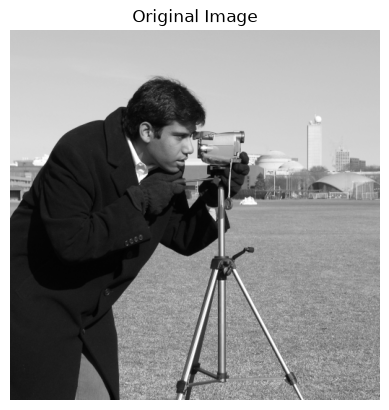

In [2]:
# ── Load image ────────────────────────────────────
# No image file was provided with the lab, so we grab a standard sample grayscale image
# (the same 'cameraman' picture used in earlier labs) and save it locally as a jpg file.
from skimage import data

img = Image.fromarray(data.camera())   # convert the sample array into a PIL Image
img.save('cameraman.jpg')              # if you have your own image, replace this with Image.open('yourfile.jpg')

print("Image size:", img.size, "| Mode:", img.mode)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

### 1. Scale (increase size)
Double the image dimensions using `Image.resize()` with high-quality resampling `(LANCZOS)`.

In [4]:
# Get the size of the image
width, height = img.size

# scaling factors
cx, cy = 2, 2   # uniform scale: double both width and height

print(f"Original size: {width}x{height}")
print(f"Target size:   {width*cx}x{height*cy}")

Original size: 512x512
Target size:   1024x1024


In [5]:
# ── 1. Increase size (scale ×2) ────────────────────
new_size = (width * cx, height * cy)

# Resize the image using PIL's built-in method
scaled_img = img.resize(new_size, Image.Resampling.LANCZOS)

Original size: (512, 512)
Scaled size:   (1024, 1024)


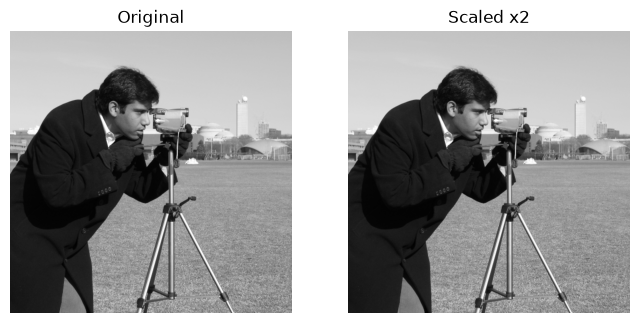

In [6]:
# Save the scaled image and print the sizes (The new image name should be "task1_1_scaled.jpg")
scaled_img.save("task1_1_scaled.jpg")

print("Original size:", img.size)
print("Scaled size:  ", scaled_img.size)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(scaled_img, cmap='gray'), plt.title('Scaled x2'), plt.axis('off')
plt.show()

 non-uniform scale (cx=2, cy=1) → stretch horizontally only

In [7]:
# Non-uniform scaling factors: stretch horizontally only (cx=2, cy=1)
cx_nu, cy_nu = 2, 1
new_size_nu = (width * cx_nu, height * cy_nu)

print(f"Original size:   {width}x{height}")
print(f"Stretched size:  {new_size_nu[0]}x{new_size_nu[1]}")

Original size:   512x512
Stretched size:  1024x512


In [8]:
# Resize using the non-uniform factors (only width changes)
stretched_img = img.resize(new_size_nu, Image.Resampling.LANCZOS)

Original size:   (512, 512)
Stretched size:  (1024, 512)


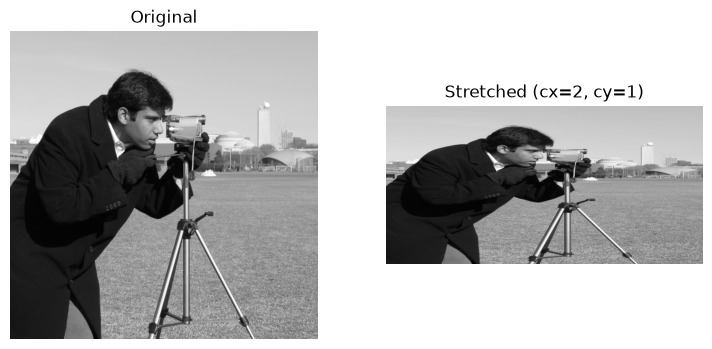

In [9]:
stretched_img.save("task1_1b_stretched.jpg")

print("Original size:  ", img.size)
print("Stretched size: ", stretched_img.size)

plt.figure(figsize=(9, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(stretched_img, cmap='gray'), plt.title('Stretched (cx=2, cy=1)'), plt.axis('off')
plt.show()

### 2. Rotate 120°
Rotate the image by 120 degrees, expanding the canvas to fit the full rotated image.

Original size: (512, 512)
Rotated size:  (700, 700)


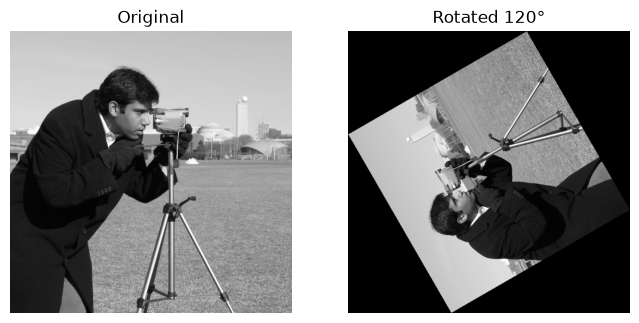

In [10]:
# ── 2. Rotate 120 degrees ──────────────────────────
rotated_img = img.rotate(120, expand=True, resample=Image.Resampling.BICUBIC)

# Save the scaled image and print the sizes (The new image name should be "task1_2_rotated.jpg")
rotated_img.save("task1_2_rotated.jpg")

print("Original size:", img.size)
print("Rotated size: ", rotated_img.size)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(rotated_img, cmap='gray'), plt.title('Rotated 120°'), plt.axis('off')
plt.show()

### 3. Shear

In [11]:
# -- c. Get the image dimensions ────────────────────
w, h = img.size
print(f"Width: {w}, Height: {h}")

Width: 512, Height: 512


In [12]:
# -- d. define the shear matrix ──────────────────────────
# Choose X-axis or Y-axis shear. The shear factor controls how much the image slants — start with 0.5 then experiment.
shear_factor = 0.5

# X-axis shear: each row is pushed sideways by an amount proportional to its row index
shx = shear_factor   # horizontal shear amount
shy = 0               # vertical shear amount (0 = no Y-axis shear)

In [13]:
# -- e. Apply the shear transformation to the image ──────────────────────────
# PIL's transform() takes the inverse affine matrix:
# [ 1    shx   tx ]
# [ shy  1     ty ]

# Shearing in X pushes pixels sideways, so we widen the canvas or part of the image gets cut off
new_w = int(w + abs(shx) * h)
new_h = h

# If the shear factor is negative, the image would shift out of view on the left, so we shift it back with tx
tx = -shx * h if shx < 0 else 0
ty = 0

sheared_img = img.transform(
    (new_w, new_h),
    Image.AFFINE,
    (1, shx, tx, shy, 1, ty),
    resample=Image.Resampling.BICUBIC
)

Original size: (512, 512)
Sheared size:  (768, 512)


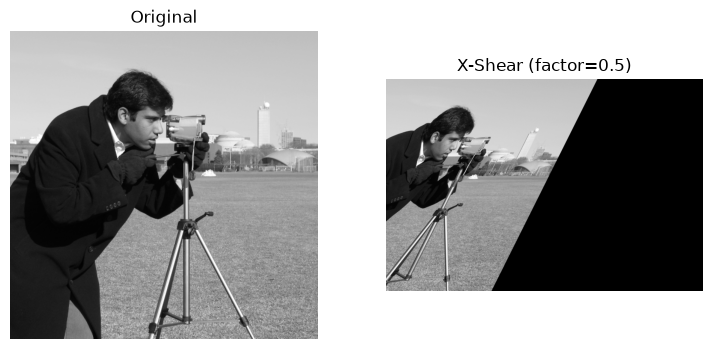

In [14]:
# -- f. Save the sheared image(The new image name should be "task1_3_sheared.jpg")
sheared_img.save("task1_3_sheared.jpg")

print("Original size:", img.size)
print("Sheared size: ", sheared_img.size)

plt.figure(figsize=(9, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(sheared_img, cmap='gray'), plt.title(f'X-Shear (factor={shear_factor})'), plt.axis('off')
plt.show()

### Experiment and compare
Try these:

— Change shear factor from 0.5 to 0.1, 0.3, 0.8 and compare results

— Switch from X-axis to Y-axis shear matrix

— Update the canvas multiplier to match your new factor

— Try combining X and Y shear in one matrix

**Observations from experimenting with the shear factor:**

- Increasing the shear factor (0.1 → 0.3 → 0.5 → 0.8) makes the slant more extreme, and the output canvas has to be made wider each time to avoid cropping the image.
- Switching `shy` (instead of `shx`) shears the image vertically — columns shift up/down instead of rows shifting left/right.
- Combining both `shx` and `shy` in the same matrix produces a diagonal "skewed" look (both directions at once).
- The canvas size formula (`new_w = w + abs(shx) * h` for X-shear, `new_h = h + abs(shy) * w` for Y-shear) must always be updated to match whatever factor is used, otherwise part of the sheared image gets cut off.

# Intensity Transformations
Negative · Log · Power Law (Gamma)

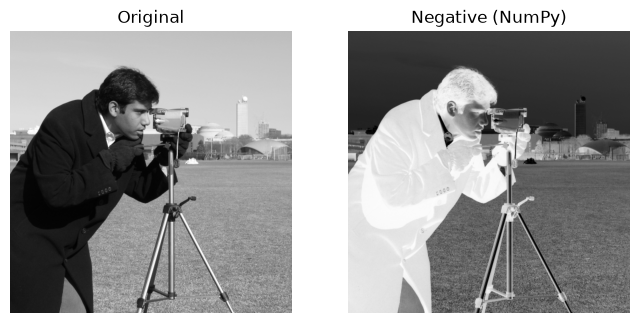

In [15]:
# ── 1. Negative ──────────────────────────────────── 
# Method 1: NumPy array manipulation
img_array = np.array(img)
negative_array = 255 - img_array
negative_img_np = Image.fromarray(negative_array.astype(np.uint8))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(negative_img_np, cmap='gray'), plt.title('Negative (NumPy)'), plt.axis('off')
plt.show()

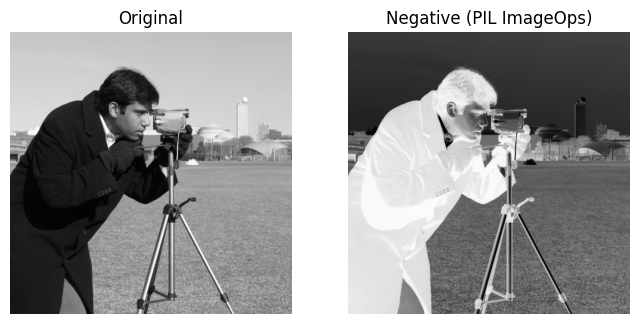

In [15]:
# Method 2: PIL's ImageOps
negative_img_pil = ImageOps.invert(img)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(negative_img_pil, cmap='gray'), plt.title('Negative (PIL ImageOps)'), plt.axis('off')
plt.show()

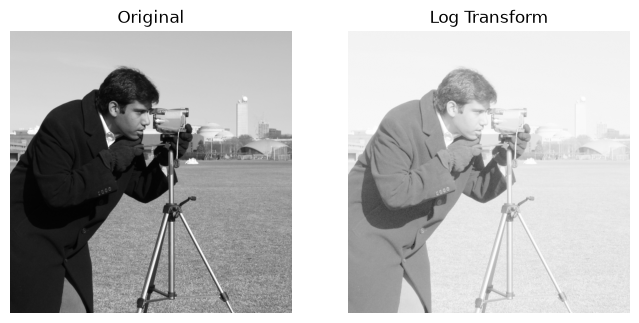

In [16]:
# ── 2. Log transformation ──────────────────────────
img_array = np.array(img, dtype=np.float64)

# s = c · log(1 + r) --> We need to find c.
# We want the maximum output value (s) to be 255 when the maximum input value (r) is 255:
# 255 = c · log(1 + 255)
# c = 255 / log(1 + 255)
c = 255 / np.log(1 + 255)

# Apply the log transformation to each pixel
log_array = c * np.log(1 + img_array)
log_img = Image.fromarray(log_array.astype(np.uint8))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(log_img, cmap='gray'), plt.title('Log Transform'), plt.axis('off')
plt.show()

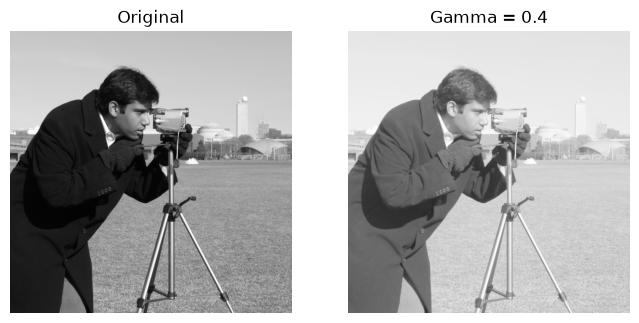

In [17]:
# ── 3. Power-law / Gamma correction ───────────────
norm_array = np.array(img, dtype=np.float64) / 255.0   # normalize pixel values to [0, 1]

gamma = 0.4   # gamma < 1 brightens the image, gamma > 1 darkens it
gamma_corrected = np.power(norm_array, gamma)
gamma_img = Image.fromarray((gamma_corrected * 255).astype(np.uint8))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(gamma_img, cmap='gray'), plt.title(f'Gamma = {gamma}'), plt.axis('off')
plt.show()

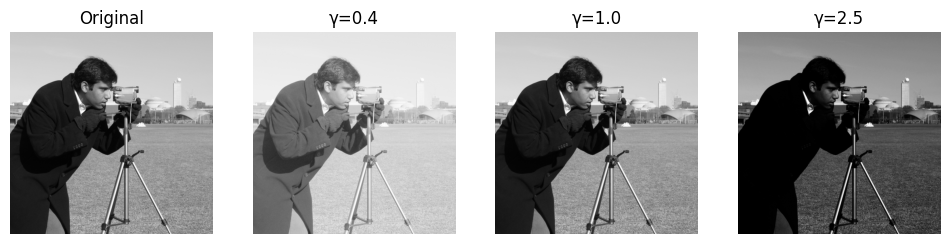

In [18]:
# Compare a few different gamma values side by side
gammas = [0.4, 1.0, 2.5]

plt.figure(figsize=(12, 3))
plt.subplot(1, len(gammas) + 1, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
for i, g in enumerate(gammas):
    corrected = np.power(norm_array, g)
    corrected_img = Image.fromarray((corrected * 255).astype(np.uint8))
    plt.subplot(1, len(gammas) + 1, i + 2)
    plt.imshow(corrected_img, cmap='gray')
    plt.title(f'γ={g}')
    plt.axis('off')
plt.show()